In [1]:
import pandas as pd

In [2]:
import seaborn as sns

In [3]:
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [4]:
sns.load_dataset('flights')

,year,month,passengers
0,1949,Jan,112
1,1949,Feb,118
2,1949,Mar,132
3,1949,Apr,129
4,1949,May,121
...,...,...,...
139,1960,Aug,606
140,1960,Sep,508
141,1960,Oct,461
142,1960,Nov,390


In [7]:
df = sns.load_dataset('iris')

In [9]:
#setosa , virginica , versi color
#labelencoder we cant provide our target variable to any encoder because it cause data leakage (y_test)

df['species'] = df['species'].apply(lambda x : 0 if x == 'setosa' else 1 if x == 'virginica' else 2)

In [12]:
df.sample(15)

,sepal_length,sepal_width,petal_length,petal_width,species
93,5.0,2.3,3.3,1.0,2
149,5.9,3.0,5.1,1.8,1
137,6.4,3.1,5.5,1.8,1
5,5.4,3.9,1.7,0.4,0
148,6.2,3.4,5.4,2.3,1
146,6.3,2.5,5.0,1.9,1
33,5.5,4.2,1.4,0.2,0
62,6.0,2.2,4.0,1.0,2
55,5.7,2.8,4.5,1.3,2
0,5.1,3.5,1.4,0.2,0


In [13]:
#imbalance or not 

#many of cases with classification we are having major issue with imbalance in dataset

df['species'].value_counts()

species
0    50
2    50
1    50
Name: count, dtype: int64

In [22]:
#split the data into X and y

X = df.drop(columns ='species')

In [15]:
y =df['species']

In [23]:
#train_test_split
from sklearn.model_selection import train_test_split

X_train , X_test , y_train , y_test = train_test_split(X,y,test_size = 0.2,random_state= 42,stratify=y)

In [24]:
X_train.shape
X_test.shape

(30, 4)

In [25]:
y_train.shape
y_test.shape

(30,)

In [26]:
from sklearn.preprocessing import StandardScaler

In [27]:
sc = StandardScaler()

In [28]:
X_train_scaled = sc.fit_transform(X_train)

In [30]:
X_test_scaled = sc.transform(X_test)

In [31]:
from sklearn.linear_model import LogisticRegression

In [32]:
model = LogisticRegression(
    random_state = 42,
    max_iter = 200
)

In [33]:
model.fit(X_train_scaled , y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",200
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in t

In [34]:
y_pred = model.predict(X_test_scaled)

In [35]:
y_test[0:5]

38     0
77     2
107    1
143    1
42     0
Name: species, dtype: int64

In [36]:
y_pred[0:5]

array([0, 1, 1, 1, 0])

In [37]:
y_prob = model.predict_proba(X_test_scaled)

In [39]:
y_prob[:5]

array([[9.77774817e-01, 3.83506173e-07, 2.22247998e-02],
       [1.69304769e-03, 5.67984747e-01, 4.30322205e-01],
       [2.16983430e-05, 9.09886334e-01, 9.00919676e-02],
       [2.93764079e-05, 9.80630769e-01, 1.93398547e-02],
       [9.88511709e-01, 2.01010360e-07, 1.14880896e-02]])

In [51]:
from sklearn.metrics import accuracy_score , confusion_matrix,classification_report

In [42]:
acc = accuracy_score(y_test,y_pred)

print(acc)

0.8666666666666667


In [43]:
cm = confusion_matrix(y_test,y_pred)

In [44]:
cm

array([[10,  0,  0],
       [ 0,  7,  3],
       [ 0,  1,  9]])

<Axes: >

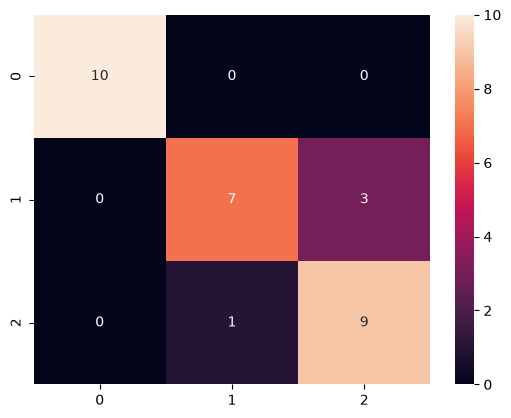

In [50]:
sns.heatmap(

    cm,
    annot=True,
)

In [52]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['setosa','versicolor','virginica']
))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.88      0.70      0.78        10
   virginica       0.75      0.90      0.82        10

    accuracy                           0.87        30
   macro avg       0.88      0.87      0.87        30
weighted avg       0.88      0.87      0.87        30



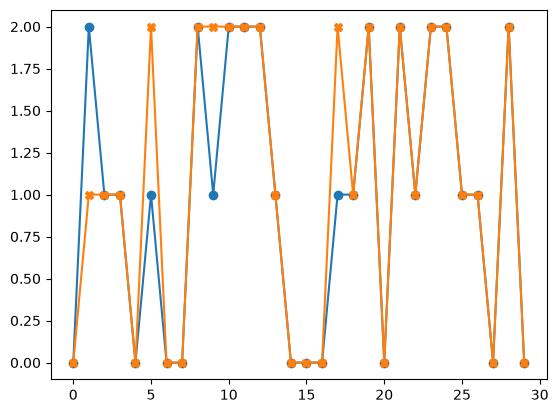

In [56]:
import matplotlib.pyplot as plt

plt.plot(
    y_test.values,
    label='Actual',
    marker ='o'
)
plt.plot(

    y_pred,
    label ='predicted',
    marker = 'X'
)
